# Enunciado
Se tiene depositos con areas $A_1$ y $A_2$, con una tuberia de coneccion de area $A_t$, y longitud $L$
![[Pasted image 20260504114459.png|224]]
Los depósitos son circulares con diametros $D_{1} = 5m\ D_{2} = 6m$ y con diametro de la tuberia $D_{t} = 1m$. 
El coeficiente de fricción de tuberia de longitud es $L = 600m$ con coef. de fricción $f = 0.024$ y perdidas menores (singulares) $K = 4.75$
La posición en el instante inicial del nivel $z_{1} = 12m$ (osea $z(t = 0) = zA_{1} / A_{t})$

1. Calcular la evolución temporal de z y la velocidad asi como la evolución de $z_1$y $z_2$. 
2. Construya el código compu-tacional basado en un metodo predictor corrector de segundo orden. ¿Cual es la diferencia entre las evoluciones temporales en los depositos?
3. ¿Cual es la influencia si el valor de la fricción se incrementa?

# Analisis
### Ecuacion con 2 depositos y friccion turbulenta
El problema comienza con el sistema de ecuaciones con una EDO de segundo orden que se dedujo en la ecuacion (9), la cual modela la dinámica de la columna de agua en todo el sistema:
$$\begin{cases}
\frac{\partial^2 z}{\partial t^2}+g\cdot \frac{A_t}{L}(\frac{1}{A_1}+\frac{1}{A_2})z+\frac{f \cdot \frac{\partial z}{\partial t} \cdot |\frac{\partial z}{\partial t}|}{2\cdot D}\cdot\frac{L_e}{L}=0 \\
v=\frac{\partial z}{\partial t} 
\end{cases}$$
Estas dos ecuaciones son exactamente lo que está dentro de la función `calcular_derivadas(t, estado)` en el codigo.

### Condiciones iniciales
Antes de iniciar el bucle numérico, el código debe entender dónde empieza el fluido. 
El problema establece que el nivel inicial en el depósito 1 es **12 m**. Sin embargo, la EDO está en función de $z$ (el desplazamiento en la tubería principal).

Con lo cual la condición inicial real para la tubería:
$$z(0) = z_1 \frac{A_1}{A_t} = 12 \left( \frac{5^2}{1^2} \right) = 12 \times 25 = 300$$

Es por esto que en tu primer gráfico, la curva azul del desplazamiento $z$ inicia exactamente en **300 m**, mientras que la velocidad inicial $v$ (curva roja) arranca en **0 m/s**.
### Metodo Predictor-Corrector
En el bucle `for` se aplica el [[Metodo de Heun]] (Predictor-Corrector de segundo orden). Funciona en dos etapas para evitar que el error numérico destabilice la oscilación:
#### Predictor
Calcula la pendiente actual ($K_1$) y usa el método de Euler básico para predecir estará el fluido en el siguiente paso de tiempo ($dt$).

_Código:_ `Y_pred = Y_actual + dt * K1`
#### Paso Corrector (El refinamiento):
Viaja a ese futuro imaginario y calcula cuál sería la pendiente allí ($K_2$). Luego, toma el promedio de ambas pendientes ($\frac{K_1 + K_2}{2}$) para dar el salto real y definitivo. 

_Código:_ `Y[i + 1] = Y_actual + (dt / 2.0) * (K1 + K2)`
# Diagrama de Flujo
![[Gemini_Generated_Image_b4uf0db4uf0db4uf-clean.png]]
# Codigo

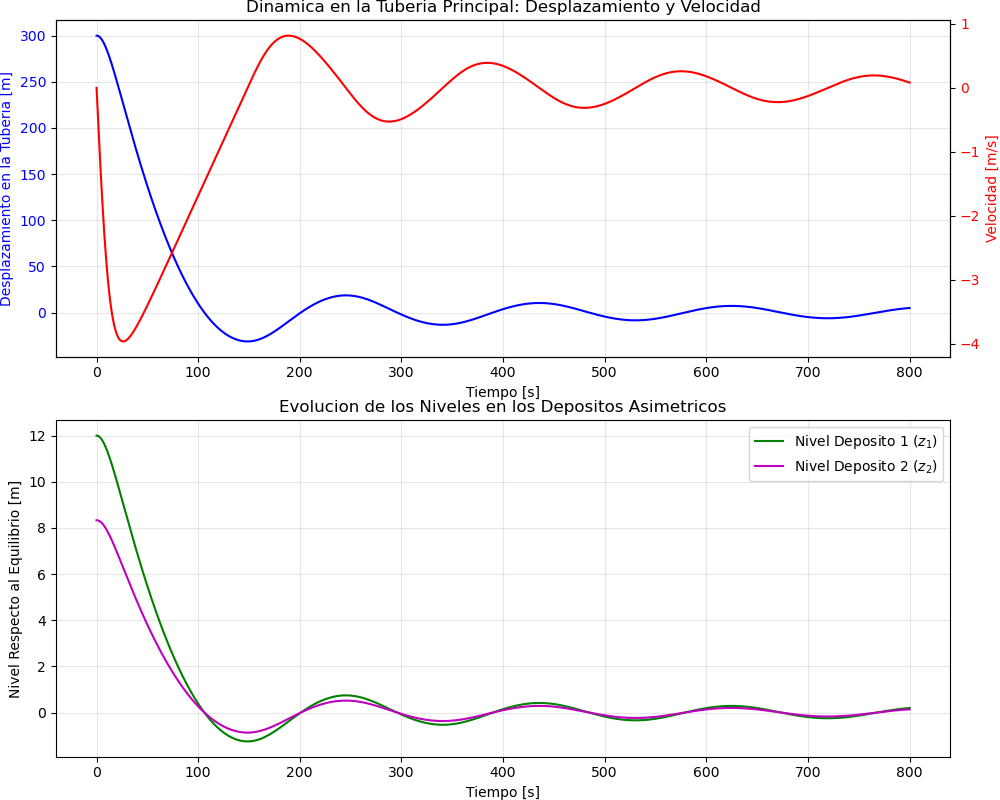

In [1]:
import numpy as np
import matplotlib.pyplot as plt

D1 = 5.0      # Diámetro depósito 1 [m]
D2 = 6.0      # Diámetro depósito 2 [m]
Dt = 1.0      # Diámetro tubería principal [m]
L = 600.0     # Longitud física de la tubería [m]
f = 0.024     # Coeficiente de fricción
K = 4.75      # Suma de pérdidas menores
g = 9.81      # Gravedad [m/s²]

# Cálculo de las áreas transversales
A1 = np.pi * (D1**2) / 4.0
A2 = np.pi * (D2**2) / 4.0
At = np.pi * (Dt**2) / 4.0

# Longitud equivalente total
Le = L + (K * Dt) / f

# Condiciones Iniciales
z1_0 = 12.0                     # Nivel inicial en el depósito 1 [m]
z_0 = z1_0 * (A1 / At)          # Desplazamiento inicial en la tubería z(0) [m]
v_0 = 0.0                       # Velocidad inicial v(0) [m/s]

# Constantes agrupadas de la EDO
C1 = g * (At / L) * (1.0 / A1 + 1.0 / A2)
C2 = (f * Le) / (2.0 * Dt * L)

def calcular_derivadas(t, estado):
    """
    Toma el vector de estado [z, v] y devuelve las derivadas [dz/dt, dv/dt].
    """
    z, v = estado
    dzdt = v
    dvdt = -C1 * z - C2 * v * np.abs(v)
    return np.array([dzdt, dvdt])

t_inicial = 0.0
t_final = 800.0   # Simular durante 800 segundos para observar la amortiguación
dt = 0.1          # Paso de tiempo [s]
pasos = int((t_final - t_inicial) / dt) + 1

tiempo = np.linspace(t_inicial, t_final, pasos)
Y = np.zeros((pasos, 2))  # Matriz de estados: Columna 0 es z, Columna 1 es v
Y[0] = [z_0, v_0]

# Bucle meodo de Heun
for i in range(pasos - 1):
    t_actual = tiempo[i]
    Y_actual = Y[i]
    
    # Pendiente en el punto actual
    K1 = calcular_derivadas(t_actual, Y_actual)
    
    Y_pred = Y_actual + dt * K1
    
    # Pendiente en el punto proyectado
    K2 = calcular_derivadas(t_actual + dt, Y_pred)
    
    Y[i + 1] = Y_actual + (dt / 2.0) * (K1 + K2)


z_tuberia = Y[:, 0]
v_tuberia = Y[:, 1]
z1_deposito = (At / A1) * z_tuberia
z2_deposito = (At / A2) * z_tuberia
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))
ax1.plot(tiempo, z_tuberia, 'b-', label='Desplazamiento z(t)')
ax1.set_xlabel('Tiempo [s]')
ax1.set_ylabel('Desplazamiento en la Tuberia [m]', color='b')
ax1.tick_params(axis='y', labelcolor='b')
ax1.grid(True, alpha=0.3)

ax1_twin = ax1.twinx()
ax1_twin.plot(tiempo, v_tuberia, 'r-', label='Velocidad v(t)')
ax1_twin.set_ylabel('Velocidad [m/s]', color='r')
ax1_twin.tick_params(axis='y', labelcolor='r')
ax1.set_title('Dinamica en la Tuberia Principal: Desplazamiento y Velocidad')

ax2.plot(tiempo, z1_deposito, 'g-', label='Nivel Deposito 1 ($z_1$)')
ax2.plot(tiempo, z2_deposito, 'm-', label='Nivel Deposito 2 ($z_2$)')
ax2.set_xlabel('Tiempo [s]')
ax2.set_ylabel('Nivel Respecto al Equilibrio [m]')
ax2.set_title('Evolucion de los Niveles en los Depositos Asimetricos')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()  

## Interpretacion Grafica
### Grafica 1 
![[Pasted image 20260504112339.png|775]]
Se Muestra un desfase, cuando el desplazamiento (azul) llega a sus picos máximos o mínimos, la velocidad (roja) es **0**. Cuando el desplazamiento cruza por el origen (equilibrio en **0**), la magnitud de la velocidad es máxima.
La amplitud decrece con cada ciclo debido al término disipativo de la fricción ($v|v|$) vista en la ecuacion (8)
### Grafica 2
![[Pasted image 20260504112356.png|775]]
Aquí se observan los niveles reales. La curva verde ($z_1$) inicia en **12 m**, y la curva magenta ($z_2$) inicia en aproximadamente **8.33 m**. 
Ambas oscilan en fase, es decir, cuando una sube, la otra también en magnitud respecto a su equilibrio) hasta converger en **0**.
# Conclusiones
## ¿Cuál es la diferencia entre las evoluciones temporales en los depósitos?

La principal diferencia es la **amplitud de la oscilación**, la cual es inversamente proporcional al area transversal de cada depósito. 

Debido a la conservación masa ($A_1 \cdot z_1 = A_2 \cdot z_2$), el mismo volumen de agua desplazado genera un mayor cambio de nivel en un diámetro menor. Como el depósito 1 es más estrecho ($D_1 =$ **5 m**) que el depósito 2 ($D_2 =$ **6 m**), la altura $z_1$ (curva verde) experimenta oscilaciones notablemente más grandes que $z_2$ (curva lila), a pesar de que ambas oscilan con la misma frecuencia y decaen en el mismo lapso de tiempo.
## ¿Cuál es la influencia si el valor de la fricción se incrementa?
Un aumento en el factor de fricción $f$ incrementa el peso del término no lineal en la ecuación 8 ($\frac{f \cdot L_e}{2 \cdot D_t \cdot L} v |v|$).

Físicamente, esto significa que el fluido disipará una mayor cantidad de energía mecánica por esfuerzo cortante ($\tau_0$), contra las paredes en cada ciclo.

En la evolución temporal, esto se traducce en una envolvente de oscilación que decae mucho más rápido mientras que las amplitudes de $z_1$ y $z_2$ se achatarían de forma abrupta, y el sistema completo alcanzaría el reposo (nivel de equilibrio $z=0$) en un tiempo considerablemente menor al mostrado en las gráficas actuales.

Este es el chat que use para Latex/overleaf
[Transitorio Depositos - Online LaTeX Editor Overleaf](https://www.overleaf.com/project/68f6afe4a3ef13186eede0c5)

# Solucion numerica Matlab
